| Grupo | Cuántas | Deflactor | Por qué |
| :--- | :--- | :--- | :--- |
| consumos | 28 | IPC | siguen los precios mes a mes |
| sueldos | 2 | RIPTE | se mueven con salarios, no con precios |
| saldos | 8 | tasa plazo fijo | crecen también por el interés |
| comisiones | 7 | moda del mes | las fija el banco, saltan de golpe |
| límites | 4 | consumo ÷ límite | quedan congelados, no se deflactan |
| dólares | 13 | tipo de cambio | ya están en otra moneda |
| crédito | 11 | tasa activa / CER | devengan interés |


1. La receta común. 

In [2]:
%run 1_home.ipynb

2. Los deflactores. Todas de datos.gob.ar, base enero 2019 = 100 donde corresponde.

- Los deflactores

Deflactar es llevar todos los montos a los precios de un mismo mes, para que
sean comparables entre meses distintos. La cuenta es siempre la misma:

    monto deflactado = monto ÷ índice del mes × índice del mes de referencia

Acá el mes de referencia es **enero 2019**: todos los montos quedan expresados
en pesos de enero 2019.

Cada grupo de variables usa el índice que le corresponde, que es el punto del
experimento: los consumos siguen los precios (IPC), los sueldos siguen a los
salarios (RIPTE), los saldos crecen además por el interés que devengan (tasa de
plazo fijo), los montos en dólares ya están en otra moneda (tipo de cambio), y
los saldos de crédito devengan la tasa activa.

Tres de los cinco índices se usan tal como los publica el organismo: el IPC del
INDEC (un índice con base diciembre 2016 = 100), el RIPTE (pesos: el sueldo
promedio del mes) y el tipo de cambio (pesos por dólar). Están en unidades
distintas y no importa: como la fórmula divide por el valor de un mes y
multiplica por el de otro, la unidad se cancela.

Los otros dos hubo que construirlos. El BCRA no publica un índice de plazo fijo
ni de préstamos, publica la **tasa** de cada mes (44,85% anual en enero, 37,62%
en febrero, y así). Una tasa no sirve para dividir: usarla directamente diría
que la plata valía más en febrero que en enero, que es exactamente al revés de
lo que pasó. Lo que hace falta es el acumulado, cuánto creció la plata desde
enero, y eso se arma mes a mes capitalizando la tasa:

    enero   = 100
    febrero = 100 × (1 + 44,85% × 30/365) = 103,69
    marzo   = 103,69 × (1 + 37,62% × 30/365) = 106,89

Hasta llegar a 152,86 en diciembre: $100 puestos a plazo fijo en enero son
$152,86 a fin de año. El arranque en 100 es una convención; con 1 como punto de
partida el resultado deflactado sería idéntico.

Fuentes: IPC INDEC (serie 148.3_INIVELNAL_DICI_M_26), RIPTE (158.1_REPTE_0_0_5),
tipo de cambio de valuación BCRA (92.1_TCV_0_0_21), tasa de plazo fijo 30-59 días
en pesos (174.1_T_INTERD_0_0_41) y tasa activa personales (89.1_TS_INTELES_0_M_32),
todas de la API de series de tiempo de datos.gob.ar.

In [3]:
MES_REFERENCIA = 201901

# IPC nacional (INDEC, serie 148.3_INIVELNAL_DICI_M_26)
IPC = {201901: 189.6101, 201902: 196.7501, 201903: 205.9571, 201904: 213.0517,
       201905: 219.5691, 201906: 225.5370, 201907: 230.4940, 201908: 239.6077,
       201909: 253.7102, 201910: 262.0661, 201911: 273.2158, 201912: 283.4442}

# RIPTE, pesos corrientes (SSS, serie 158.1_REPTE_0_0_5)
RIPTE = {201901: 35362.23, 201902: 36733.68, 201903: 38884.43, 201904: 39658.15,
         201905: 40911.09, 201906: 41584.20, 201907: 43290.96, 201908: 44092.81,
         201909: 45485.23, 201910: 47834.32, 201911: 48591.60, 201912: 49574.33}

# Tipo de cambio de valuación, pesos por dólar (BCRA, serie 92.1_TCV_0_0_21)
TIPO_CAMBIO = {201901: 37.3959, 201902: 38.3400, 201903: 41.1895, 201904: 43.1066,
               201905: 44.8809, 201906: 43.7834, 201907: 42.4508, 201908: 52.4645,
               201909: 56.5866, 201910: 58.5145, 201911: 59.7272, 201912: 59.8785}

# Plazo fijo 30-59 días en pesos, capitalizado mes a mes (BCRA, 174.1_T_INTERD_0_0_41)
PLAZO_FIJO = {201901: 100.0000, 201902: 103.6865, 201903: 106.8925, 201904: 110.3338,
              201905: 114.5396, 201906: 119.2888, 201907: 124.1843, 201908: 129.0302,
              201909: 134.6608, 201910: 141.0717, 201911: 147.3585, 201912: 152.8582}

# Tasa activa personales, capitalizada mes a mes (BCRA, 89.1_TS_INTELES_0_M_32)
TASA_ACTIVA = {201901: 100.0000, 201902: 105.2660, 201903: 110.6484, 201904: 116.1778,
               201905: 122.2098, 201906: 128.9408, 201907: 136.0456, 201908: 143.4066,
               201909: 151.5265, 201910: 161.0665, 201911: 171.0760, 201912: 181.5149}

3. Los grupos.

In [4]:
GRUPOS = {
    "consumos": [
        "mautoservicio", "mtarjeta_visa_consumo", "mtarjeta_master_consumo", "mpagodeservicios",
        "mpagomiscuentas", "mcuenta_debitos_automaticos", "mttarjeta_visa_debitos_automaticos",
        "mttarjeta_master_debitos_automaticos", "mextraccion_autoservicio", "matm", "matm_other",
        "mcheques_depositados", "mcheques_emitidos", "mcheques_depositados_rechazados",
        "mcheques_emitidos_rechazados", "mtransferencias_recibidas", "mtransferencias_emitidas",
        "mcajeros_propios_descuentos", "mtarjeta_visa_descuentos", "mtarjeta_master_descuentos",
        "Master_mconsumospesos", "Master_mconsumototal", "Master_mpagado", "Master_mpagospesos",
        "Visa_mconsumospesos", "Visa_mconsumototal", "Visa_mpagado", "Visa_mpagospesos",
    ],
    "sueldos": ["mpayroll", "mpayroll2"],
    "saldos": [
        "mcuenta_corriente", "mcuenta_corriente_adicional", "mcaja_ahorro", "mcaja_ahorro_adicional",
        "mcuentas_saldo", "mplazo_fijo_pesos", "minversion1_pesos", "minversion2",
    ],
    "comisiones": [
        "mcomisiones", "mcomisiones_mantenimiento", "mcomisiones_otras",
        "mrentabilidad", "mrentabilidad_annual", "mactivos_margen", "mpasivos_margen",
    ],
    "limites": [
        "Master_mfinanciacion_limite", "Master_mlimitecompra",
        "Visa_mfinanciacion_limite", "Visa_mlimitecompra",
    ],
    "dolares": [
        "mcaja_ahorro_dolares", "mplazo_fijo_dolares", "minversion1_dolares", "mforex_buy", "mforex_sell",
        "Master_msaldodolares", "Master_mconsumosdolares", "Master_madelantodolares", "Master_mpagosdolares",
        "Visa_msaldodolares", "Visa_mconsumosdolares", "Visa_madelantodolares", "Visa_mpagosdolares",
    ],
    "credito": [
        "mprestamos_personales", "mprestamos_prendarios", "mprestamos_hipotecarios",
        "Master_msaldototal", "Master_msaldopesos", "Master_madelantopesos", "Master_mpagominimo",
        "Visa_msaldototal", "Visa_msaldopesos", "Visa_madelantopesos", "Visa_mpagominimo",
    ],
}

## Los grupos

Las 73 columnas monetarias del dataset —las que empiezan con `m`, `Master_m` o
`Visa_m`— se reparten en siete grupos según **quién pone el número y cómo se
ajusta**. Esa es la decisión conceptual del experimento: el modelo que divide
todo por el IPC supone que las 73 se mueven igual, y no es así.

| Grupo | Columnas | Deflactor | Por qué |
|---|---|---|---|
| consumos | 28 | IPC | lo que el cliente gasta sigue los precios mes a mes |
| sueldos | 2 | RIPTE | se mueven con las paritarias, no con los precios |
| saldos | 8 | tasa de plazo fijo | además de perder contra la inflación, devengan interés |
| comisiones | 7 | valor modal del mes | las fija el banco: quedan quietas y saltan de golpe |
| límites | 4 | ninguno (ratio de uso) | quedan congelados meses; deflactarlos inventa una caída |
| dólares | 13 | tipo de cambio | ya están en otra moneda |
| crédito | 11 | tasa activa | los saldos devengan la tasa a la que se prestó |

Dos casos merecen aclaración.

**Las comisiones** no tienen un índice oficial que las represente, así que se
construye uno desde los propios datos: el valor más frecuente de
`mcomisiones_mantenimiento` en cada mes, que es el precio de lista que el banco
le cobra a la mayoría. Armar un índice de precios a partir de registros de
transacciones es el método que el *Consumer Price Index Manual* (FMI, 2020)
trata en su capítulo de scanner data.

**Los límites no se deflactan.** Un límite de compra puede quedar congelado un
año entero: no es un precio que se ajuste, es un tope que el banco revisa cuando
quiere. Dividirlo por el IPC le inventaría una caída mensual que nunca ocurrió.
Lo que sí informa es cuánto de ese límite está usando el cliente, así que se
agregan cuatro ratios —consumo sobre límite de compra y saldo sobre límite de
financiación, para Master y Visa— y los límites quedan en valores nominales.

Esto hace que este modelo tenga cuatro columnas más que los otros dos, y por lo
tanto veinte features más una vez calculados los lags y deltas. Es una diferencia
deliberada, parte de tratar a los límites distinto, y hay que tenerla presente al
leer la comparación.

4. El índice de comisiones, construido desde los datos (el valor más frecuente de cada mes, que es tu justificación de scanner data).

In [5]:
def indice_comisiones(df, columna="mcomisiones_mantenimiento", mes_ref=MES_REFERENCIA):
    modas = (df[df[columna] > 0].groupby("foto_mes")[columna]
             .agg(lambda s: s.round(2).mode().iloc[0]))
    return (modas / modas.loc[mes_ref] * 100).to_dict()

5. Deflactar cada grupo con el suyo. Los límites no se deflactan: se les agrega el ratio de uso.

In [6]:
def deflactar_grupos(df, mes_ref=MES_REFERENCIA):
    out = df.copy()
    indices = {
        "consumos": IPC,
        "sueldos": RIPTE,
        "saldos": PLAZO_FIJO,
        "comisiones": indice_comisiones(df),
        "dolares": TIPO_CAMBIO,
        "credito": TASA_ACTIVA,
    }
    for grupo, indice in indices.items():
        cols = GRUPOS[grupo]
        factor = df.foto_mes.map(indice).astype("float32")
        out[cols] = out[cols].astype("float32").div(factor, axis=0) * indice[mes_ref]

    # los límites quedan nominales; lo que informa es cuánto del límite se usa
    for tarjeta in ("Master", "Visa"):
        out[f"{tarjeta}_ratio_consumo_limite"] = (
            df[f"{tarjeta}_mconsumototal"] / df[f"{tarjeta}_mlimitecompra"].replace(0, np.nan))
        out[f"{tarjeta}_ratio_saldo_financiacion"] = (
            df[f"{tarjeta}_msaldototal"] / df[f"{tarjeta}_mfinanciacion_limite"].replace(0, np.nan))
    return out

6. Deflactar y después las históricas.

In [7]:
df = cargar_datos()
df_grupos = deflactar_grupos(df)
datos, features = agregar_lags_deltas(df_grupos)
print(datos.shape, len(features))

(1563565, 783) 780


7. Su propia BO.

In [8]:
import os, shutil

ESTUDIO_LOCAL = "/home/ds/datasets/optuna_grupos.db"
ESTUDIO_BUCKET = "/home/ds/buckets/b1/optuna_grupos.db"

if not os.path.exists(ESTUDIO_LOCAL) and os.path.exists(ESTUDIO_BUCKET):
    shutil.copy(ESTUDIO_BUCKET, ESTUDIO_LOCAL)

estudio_grupos = optimizar(datos, features, "deflactado_grupos",
                           storage=f"sqlite:///{ESTUDIO_LOCAL}")

shutil.copy(ESTUDIO_LOCAL, ESTUDIO_BUCKET)

[I 2026-11-19 07:51:19,693] Using an existing study with `study_name='deflactado_grupos'` instead of creating a new one.


[deflactado_grupos] trials completos: 50, faltan: 0
[deflactado_grupos] mejor AUC 0.93121
[deflactado_grupos] {'num_leaves': 198, 'learning_rate': 0.013053761677382196, 'min_data_in_leaf': 999, 'feature_fraction': 0.5752229718027395, 'bagging_fraction': 0.4427029714618993}


'/home/ds/buckets/b1/optuna_grupos.db'

8. Las mismas 5 semillas.

In [9]:
res_grupos, curvas_grupos, probas_grupos = correr_semillas(datos, features, estudio_grupos)
res_grupos.to_csv("/home/ds/buckets/b1/grupos_5semillas.csv", index=False)
res_grupos

  semilla 100129: $282,920,000 con 4,712 envios (200s)
  semilla 100183: $287,870,000 con 5,532 envios (264s)
  semilla 100151: $283,085,000 con 5,626 envios (199s)
  semilla 500041: $286,275,000 con 4,430 envios (274s)
  semilla 900007: $284,295,000 con 3,982 envios (206s)
media $284,889,000  desvio $2,138,432


,semilla,ganancia,envios
0,100129,282920000.0,4712
1,100183,287870000.0,5532
2,100151,283085000.0,5626
3,500041,286275000.0,4430
4,900007,284295000.0,3982


9. Los tres modelos juntos.

IPC único: $286,418,000   grupos: $284,889,000
diferencia media: $-1,529,000  (-0.53%)
gana el experimento en 1 de 5 semillas
Wilcoxon necesita al menos 6 pares para dar un p confiable


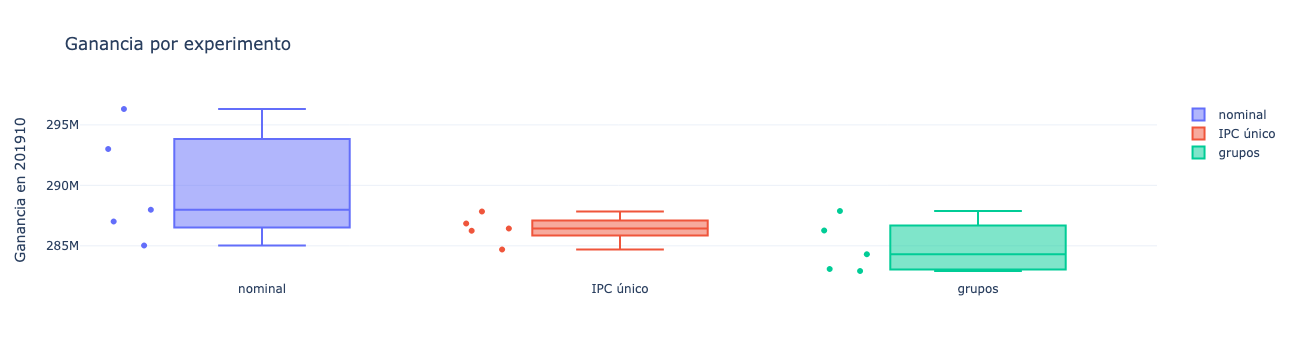

In [10]:
res_base = pd.read_csv("/home/ds/buckets/b1/baseline_5semillas.csv")
res_ipc = pd.read_csv("/home/ds/buckets/b1/ipc_5semillas.csv")

comparar(res_ipc, res_grupos, "IPC único", "grupos")
grafico_comparacion({"nominal": res_base, "IPC único": res_ipc, "grupos": res_grupos}).show()

In [11]:
# --- 20 semillas: 15 nuevas que se suman a las 5 que ya estan ---
NOMBRE  = "grupos"
ESTUDIO = "deflactado_grupos"

SEMILLAS_EXTRA = [100193, 100207, 100213, 100237, 100267,
                  100271, 100279, 100291, 100297, 100313,
                  500069, 500083, 500107, 500111, 900017]

import optuna, shutil, pandas as pd
shutil.copy(f"/home/ds/buckets/b1/optuna_{NOMBRE}.db",
            f"/home/ds/datasets/optuna_{NOMBRE}.db")
est = optuna.load_study(study_name=ESTUDIO,
                        storage=f"sqlite:////home/ds/datasets/optuna_{NOMBRE}.db")

extra, _, _ = correr_semillas(datos, features, est, semillas=SEMILLAS_EXTRA)
viejas = pd.read_csv(f"/home/ds/buckets/b1/{NOMBRE}_5semillas.csv")
res20  = pd.concat([viejas, extra], ignore_index=True)
res20.to_csv(f"/home/ds/buckets/b1/{NOMBRE}_20semillas.csv", index=False)

print(f"{NOMBRE}: media ${res20.ganancia.mean():,.0f}  "
      f"desvio ${res20.ganancia.std():,.0f}  n={len(res20)}")

  semilla 100193: $284,652,500 con 3,409 envios (203s)
  semilla 100207: $284,322,500 con 4,901 envios (199s)
  semilla 100213: $283,030,000 con 4,508 envios (233s)
  semilla 100237: $283,937,500 con 4,115 envios (267s)
  semilla 100267: $283,360,000 con 2,896 envios (202s)
  semilla 100271: $287,980,000 con 4,968 envios (268s)
  semilla 100279: $286,935,000 con 4,766 envios (273s)
  semilla 100291: $282,287,500 con 5,055 envios (207s)
  semilla 100297: $287,485,000 con 4,146 envios (199s)
  semilla 100313: $282,810,000 con 5,276 envios (193s)
  semilla 500069: $285,037,500 con 4,955 envios (200s)
  semilla 500083: $284,762,500 con 6,285 envios (198s)
  semilla 500107: $287,595,000 con 4,782 envios (268s)
  semilla 500111: $283,140,000 con 3,384 envios (203s)
  semilla 900017: $285,450,000 con 5,380 envios (205s)
media $284,852,333  desvio $1,877,682
grupos: media $284,861,500  desvio $1,887,023  n=20


=== nominal vs IPC ===
nominal: $290,571,875   IPC único: $287,320,000
diferencia media: $-3,251,875  (-1.12%)
gana el experimento en 1 de 20 semillas
Wilcoxon pareado: p = 0.0001

=== nominal vs grupos ===
nominal: $290,571,875   grupos: $284,861,500
diferencia media: $-5,710,375  (-1.97%)
gana el experimento en 1 de 20 semillas
Wilcoxon pareado: p = 0.0000

=== IPC vs grupos ===
IPC único: $287,320,000   grupos: $284,861,500
diferencia media: $-2,458,500  (-0.86%)
gana el experimento en 5 de 20 semillas
Wilcoxon pareado: p = 0.0012


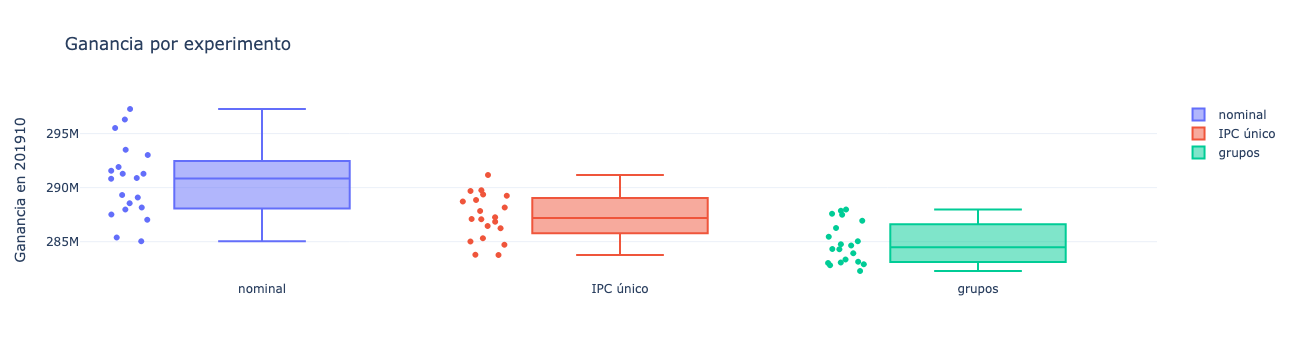

In [12]:

b20 = pd.read_csv("/home/ds/buckets/b1/baseline_20semillas.csv")
i20 = pd.read_csv("/home/ds/buckets/b1/ipc_20semillas.csv")
g20 = pd.read_csv("/home/ds/buckets/b1/grupos_20semillas.csv")

print("=== nominal vs IPC ===");    comparar(b20, i20, "nominal", "IPC único")
print("\n=== nominal vs grupos ==="); comparar(b20, g20, "nominal", "grupos")
print("\n=== IPC vs grupos ===");    comparar(i20, g20, "IPC único", "grupos")

grafico_comparacion({"nominal": b20, "IPC único": i20, "grupos": g20}).show()


In [13]:
print(f"grupos: media ${g20.ganancia.mean():,.0f} desvio ${g20.ganancia.std():,.0f}  envios {g20.envios.min():,}-{g20.envios.max():,}")
print(f"nominal: envios {b20.envios.min():,}-{b20.envios.max():,}   ipc: envios {i20.envios.min():,}-{i20.envios.max():,}")

grupos: media $284,861,500 desvio $1,887,023  envios 2,896-6,285
nominal: envios 3,075-5,625   ipc: envios 3,831-5,834
